In [ ]:
# --- Setup: dependencies and data ---------------------------------------------
# The notebook needs three CATH_s20 files. They are taken from, in this order:
#   1. the folder DATA_DIR, if they are already there
#   2. the Colab file browser (uploaded into /content), if they were dropped there
#   3. the public SNNEED repository on GitHub
#   4. an upload dialog, if the download fails
# Each file is then checked for the columns the notebook reads.

!pip install rapidfuzz --quiet

import os, shutil, urllib.request
import pandas as pd

DATA_DIR = 'data'
DATA_URL = 'https://raw.githubusercontent.com/katzemelli/SNNEED/main/data'

# file name -> columns the notebook reads from it
DATA_FILES = {
    'cath_s20_train70.csv.gz': ['domain_id', 'aa_seq', 'ss_seq'],
    'cath_s20_test30.csv.gz':  ['domain_id', 'aa_seq', 'ss_seq'],
    'cath_s20_3di.csv.gz':     ['domain_id', '3di'],
}

os.makedirs(DATA_DIR, exist_ok=True)

for name in DATA_FILES:
    path = f'{DATA_DIR}/{name}'

    if os.path.exists(path):
        print(f'found       {path}')
        continue

    if os.path.exists(name):                       # uploaded via the file browser
        shutil.move(name, path)
        print(f'moved       {name} -> {path}')
        continue

    try:
        urllib.request.urlretrieve(f'{DATA_URL}/{name}', path)
        print(f'downloaded  {path}')
    except Exception as e:
        print(f'download of {name} failed ({e}) - please upload it')
        from google.colab import files
        uploaded = files.upload()                  # opens a file picker
        if name not in uploaded:
            raise FileNotFoundError(f'{name} was not uploaded')
        with open(path, 'wb') as fh:
            fh.write(uploaded[name])
        os.remove(name)                            # files.upload also saves a copy in /content
        print(f'uploaded    {path}')

# --- shape check: every file must contain the columns the notebook reads ---
for name, needed in DATA_FILES.items():
    columns = list(pd.read_csv(f'{DATA_DIR}/{name}', nrows=5).columns)
    missing = [c for c in needed if c not in columns]
    if missing:
        raise ValueError(f'{name} is missing column(s) {missing}; it has {columns}')
print('data OK')

# Constants, colours and cache

Colour palette, labels and order are locked in for consistent output.

In [ ]:
import os, json, time, pickle
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import sparse
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from rapidfuzz.distance import Levenshtein as RFLev
from rapidfuzz.process import cdist as rf_cdist

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

# DATA_DIR is set in the setup cell above

# --- CONSTANTS ---

AA_ALPHABET = 'ACDEFGHIKLMNPQRSTVWY'; SS_ALPHABET = 'HLS'
CHAR_TO_IDX = {c: i for i, c in enumerate(AA_ALPHABET)}; PAD_IDX = 20; VOCAB = 21
MIN_LEN, MAX_LEN, BS, K = 50, 200, 128, 16
RANGE_LOW, RANGE_HIGH = 0.30, 0.70          # Table 2.1
RESCUED = {'4z0mC02', '3qkaE02'}
N_TRAIN, EPOCHS, LR = 30_000, 30, 1e-3
SEEDS = [0, 1, 2]
STRAT_CAND, STRAT_PER_BIN = 200_000, 400
PAIR_SEED = 999
SYN_DEP, SYN_INDEP, SYN_SEED = 20_000, 8_000, 20260810
ESM2_MODEL = 'facebook/esm2_t12_35M_UR50D'
TIE_REPS, TIE_SEED = 200, 1234              # Tie handling for MAP/ AUROC

# --- labels, order and colour ---

METHODS = ['SNNEED', 'ESM-2', 'Dice', 'Length']
DATASETS = ['Synth', '3Di', 'SS', 'AA']
COLOUR = {'SNNEED': '#C026A6',
          'ESM-2': '#2CA02C',
          'Dice': '#9E9E9E',
          'Length': '#8C564B',
          'Synth': '#FF7F0E',
          '3Di': '#0072B2',
          'SS': '#D62728',
          'AA': '#4D4D4D'}

AA_SET, SS_SET = set(AA_ALPHABET), set(SS_ALPHABET)
is_aa = lambda x: all(c in AA_SET for c in x)
is_ss = lambda x: all(c in SS_SET for c in x)
def norm_lev(x, y):
  L = max(len(x), len(y))
  if L == 0:
    return 1.0
  return 1.0 - RFLev.distance(x, y) / L

# --- Cache ---
# keep ?

# Build Collections

downloads, assembles and builds datasets and reorganises them into:

**1. Datasets**

*   AA, 3Di, SS (real CATH_s20 data)
*   Synth train (2.3.1)

**2. Evaluation Sets (2.6)**

*   Synth Eval (2.4.2)
*   Exact Relevance Sets (2.6.1)
*   Decile-Balanced Pairwise Evaluation Set (2.6.2)






In [ ]:
# --- CATH_s20 Collections ---

raw = pd.concat([pd.read_csv(f'{DATA_DIR}/cath_s20_train70.csv.gz'),
                 pd.read_csv(f'{DATA_DIR}/cath_s20_test30.csv.gz')],
                ignore_index=True).drop_duplicates('domain_id')
seqs3 = pd.read_csv(f'{DATA_DIR}/cath_s20_3di.csv.gz')

def _valid(seq, isstd, d):
    return (isinstance(seq, str) and isstd(seq)
            and ((MIN_LEN <= len(seq) <= MAX_LEN) or d in RESCUED))

COLL = {
    'AA':  [s for d, s in zip(raw['domain_id'], raw['aa_seq'])              if _valid(s, is_aa, d)],
    'SS':  [s for d, s in zip(raw['domain_id'], raw['ss_seq'])              if _valid(s, is_ss, d)],
    '3Di': [s for d, s in zip(seqs3['domain_id'], seqs3['3di'].astype(str)) if _valid(s, is_aa, d)],
}
for f in ['AA', 'SS', '3Di']:
    print(f'  {f:<4} {len(COLL[f]):>6,} sequences')


**Synth**
1. Train (2.3.1)
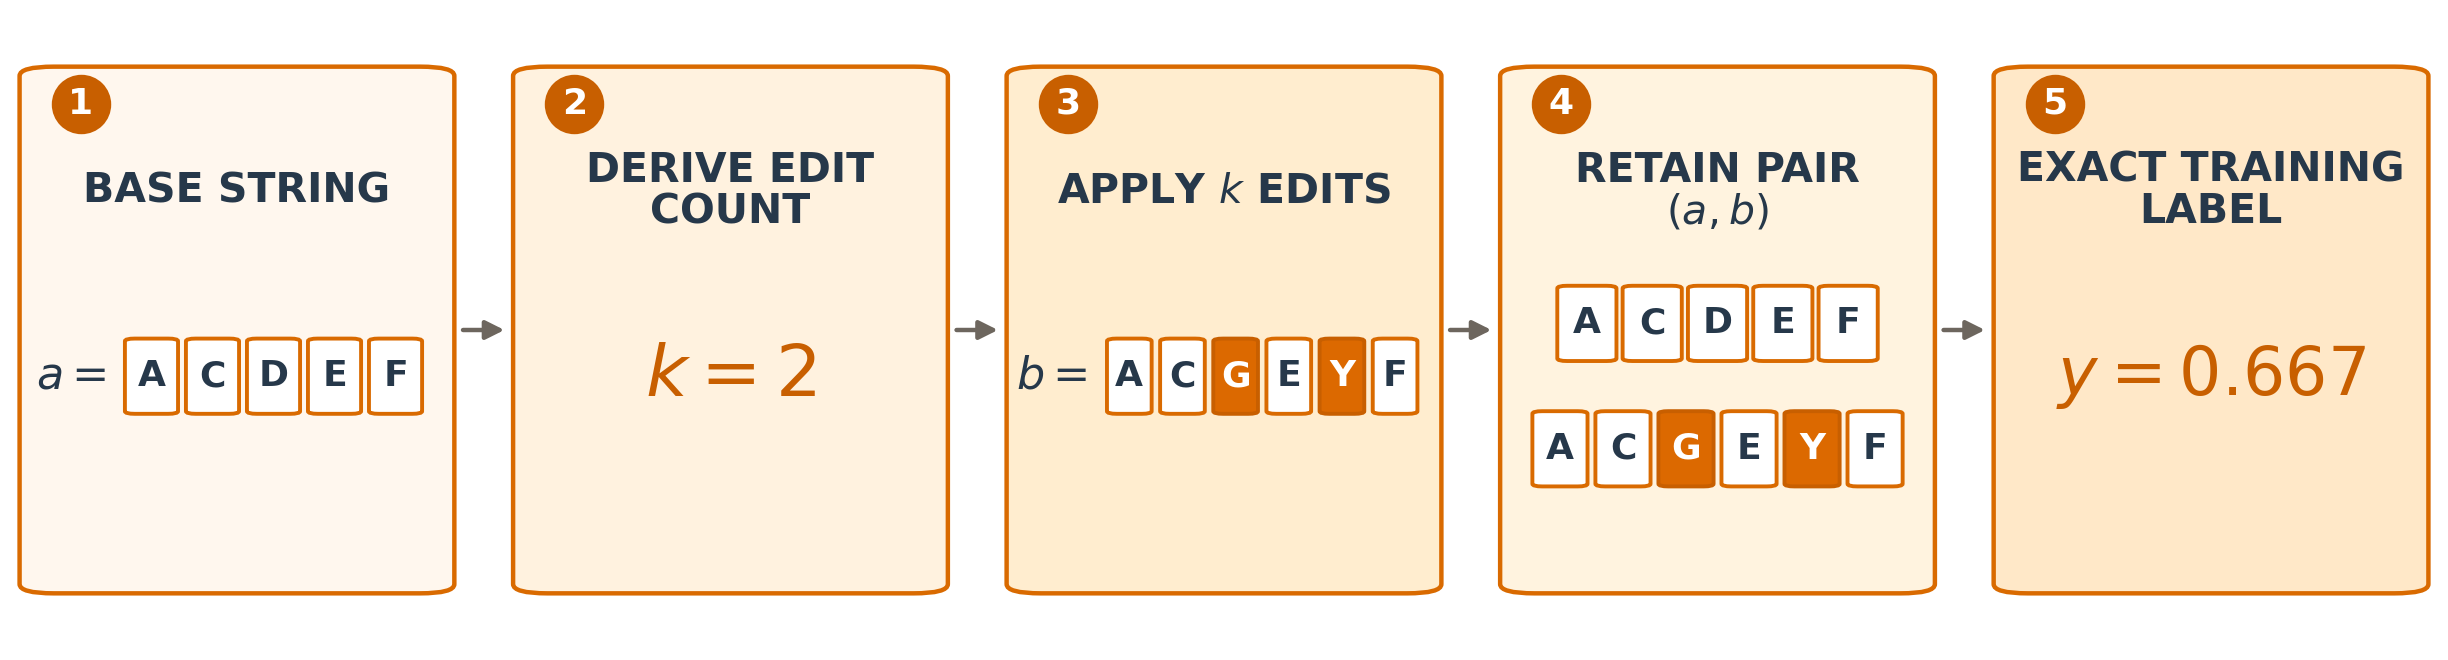

2. Eval (2.4.2)

In [ ]:

'''
┌─────────────────────────────────────────┐
│                                         │
│            Synth Train 2.3.1            │
│                                         │
└─────────────────────────────────────────┘
'''

def rand_seq(abc, rng):
  # Step 1
  L = int(rng.integers(MIN_LEN, MAX_LEN + 1))
  return ''.join(rng.choice(list(abc), L))

def gen_seq(seq, k, abc, rng):
  # Step 2 - 3
  # applies k random edits to the original sequence to create a new sequence
  s = list(seq)
  abc = list(abc)

  for _ in range(k):
      if len(s) == 0:
        op = 'ins'
      elif len(s) >= MAX_LEN:
        op = rng.choice(['sub', 'del'])
      else:
        op = rng.choice(['sub', 'ins', 'del'])
      if op == 'sub':
        i = rng.integers(0, len(s))
        s[i] = rng.choice([c for c in abc if c != s[i]])
      elif op == 'ins':
        i = rng.integers(0, len(s) + 1)
        s.insert(i, rng.choice(abc))
      else:
        i = rng.integers(0, len(s))
        del s[i]
  return ''.join(s)


'''
┌─────────────────────────────────────────┐
│                                         │
│            Synth Eval 2.4.2             │
│                                         │
└─────────────────────────────────────────┘
'''

def build_synth_eval(seed=SYN_SEED):
  # Combines 20,000 dependent with 8,000 independent, low similarity pairs
  # differs also from Synth Train in how edit count is drawn
  r = np.random.default_rng(seed)
  recs = []
  for _ in range(SYN_DEP):
        base = rand_seq(AA_ALPHABET, r)
        part = gen_seq(base, int(r.integers(0, len(base) + 1)), AA_ALPHABET, r)
        if 1 <= len(part) <= MAX_LEN: recs.append((base, part))
  for _ in range(SYN_INDEP):
    recs.append((rand_seq(AA_ALPHABET, r), rand_seq(AA_ALPHABET, r)))
  recs = [(a, b, norm_lev(a, b)) for a, b in recs]
  nl_all = np.array([x[2] for x in recs]) # pulls normLev column from triple (a, b, score)

  # --- create decile balanced subset for evaluation 2.6.2  ---
  bins = np.clip(np.digitize(nl_all, np.linspace(0, 1, 11)) - 1, 0, 9)
  take = []
  for bb in range(10): # 10 decile "bins" for normLev score 0.0 - 1.0
    idx = np.where(bins == bb)[0] # boolean
    if idx.size: take.extend(r.permutation(idx)[:STRAT_PER_BIN].tolist()) # keeps at most 400 samples

  # --- create array structure every scoring method downstream expects ---
  # seqs: every sequence as a flat list, pair members adjacent
  # I, J: parallel arrays of postions, so pair x is (seqs[I[x]], seqs[J[x]])
  # NL  : ground - truth normLev for pair x, aligned to the same x.
  seqs, I, J, NL = [], [], [], []
  for idx in take:
      a, b, l = recs[int(idx)]
      I.append(len(seqs)); seqs.append(a)
      J.append(len(seqs)); seqs.append(b)
      NL.append(l)
  return seqs, np.array(I), np.array(J), np.array(NL), nl_all

print('generating the Synth evaluation collection ...')
COLL['Synth'], SYN_I, SYN_J, SYN_NL, SYN_NL_ALL = build_synth_eval()
print(f'  {len(COLL["Synth"]):,} sequences, {len(SYN_NL):,} balanced pairs')

**Exact relevance set for synth** (2.6.1)

Every sequence is compared with every other sequence in the same search collection using exact normalised Levenshtein similarity. Comparisons are performed only within the same dataset and representation. AA sequences are therefore compared only with AA sequences, SS with SS, 3Di with 3Di and synthetic strings with synthetic strings. For each sequence, its relevance set contains every other sequence whose exact normalised Levenshtein similarity is at least 0.70.

A sequence is used as a retrieval query only if this relevance set is non-empty. Only the members of each relevance set and their exact similarities are required for evaluation, not the full matrix of comparisons.

In [ ]:
def build_relevance(seqs, block=1024, tag=''):
  '''

   seqs = list of strings, e.g. AA, SS or 3Di sequences
   block = how many query rows are processed at a time
   tag = progress label for printout, not necessary for logic itself
   T_high = dictionary | query index to array of indices of its high-sim neighbours
            which delivers the fast, right answers for a query i.
   pos = list if unique positive pairs (i, j, sim), each pair stored once

  '''

  N = len(seqs)
  lens = np.array([len(s) for s in seqs])
  T_high, pos = {}, []
  t0 = time.time()

  for r0 in range(0, N, block):
      r1 = min(r0 + block, N)
      # D[a, j] is the number of edits between query r0+a and sequence j,
      # one row per query, one column per sequence.
      # rf_cdist computes the whole block at once in C++ on all CPU cores (workers=-1);
      # .astype(np.float64) turns the integer edit counts into floats for the division below.
      D = rf_cdist(seqs[r0:r1], seqs, scorer=RFLev.distance, workers=-1).astype(np.float64)

      # CHANGED to rf_cdist for speed. The written-out version below gives the same D,
      # but makes ~350 million single Python calls on one CPU core across all four
      # datasets (tens of minutes instead of about one). Kept for reference:
      #
      # queries = seqs[r0:r1]
      # D = np.zeros((len(queries), len(seqs)))   # np.zeros is float64 already
      # for a in range(len(queries)):
      #   for j in range(len(seqs)):
      #     D[a, j] = RFLev.distance(queries[a], seqs[j])


      den = np.maximum(lens[r0:r1][:, None], lens[None, :])
      # normalisation denominator for every pair, shaped into [column][row]
      # so result is (chunk, N) matrix
      den[den == 0] = 1   # no 0 division
      sim = 1.0 - D / den # normLev as defined in 2.1
      for a in range(r1 - r0):
          i = r0 + a
          row = sim[a].copy() # copied so the query doesn't change sim
          row[i] = -1.0       # removes self similarity
          hi = np.where(row >= RANGE_HIGH)[0] # high-sim filter
          if hi.size: # populates T_high dictionary
              T_high[i] = hi.astype(np.int32)
              for j in hi:
                  if j > i: pos.append((i, int(j), float(row[j])))
      print(f'    {tag} {r1:>6,}/{N:,}  ({time.time()-t0:.0f}s)', end='\r')
  print()
  return dict(T_high=T_high, pos_pairs=pos)

REL = {}
for f in DATASETS:
  print(f'{f}. exact relevance-set scan over {len(COLL[f]):,} sequences')
  REL[f] = build_relevance(COLL[f], tag=f)

for f in DATASETS:
  print(f'{f:<6} high-similarity pairs = {len(REL[f]["pos_pairs"]):>8,}'
        f'   eligible queries = {len(REL[f]["T_high"]):>7,}')



**Decile-balanced pair sets 2.6.2**


The natural similarity distributions described in Section 2.4 and shown in Figure A.1 differ substantially between datasets.

Sampling pairs in proportion to their natural frequency would therefore produce almost no high-similarity AA pairs but thousands of high-similarity SS pairs. The same metric would consequently focus on different parts of the similarity scale in each dataset. Balancing makes every similarity range comparably represented in every dataset, which allows for a fair spearman rank correlation across datasets.

The candidate pairs are divided into ten intervals of equal width on the sLev scale.

 **Interval k** contains every pair with k/10 ≤ sLev < (k + 1)/10 for k = 0,...,8, and the tenth interval additionally includes sLev = 1.



- At most **400 pairs are retained** from each occupied interval.
- self-pairs discarded.
- all high-similarity pairs injected.
- ten equal-width intervals.

In [ ]:
def build_balanced(feed, rng):
  '''
  Builds one feed's pair set.

  '''
  seqs = COLL[feed] # gets corresponding seq list
  N = len(seqs)     # N = amount of sequences
  a = rng.integers(0, N, STRAT_CAND) # draw a, b random sequences
  b = rng.integers(0, N, STRAT_CAND)
  keep = a != b
  a, b = a[keep], b[keep]
  # compute normLev for every random pair a,b
  nl = np.array([norm_lev(seqs[i], seqs[j]) for i, j in zip(a, b)])
  if REL[feed]['pos_pairs']:
    # pos_pair from build_relevance (all pairs high-sim)
    # append those high-sim pairs to the pool
    # pa turns list (i, j, sim) into array with 3 columns
    # column 0 is i, 1 is j, 2 is sim
    pa = np.array(REL[feed]['pos_pairs'], dtype=float)
    a  = np.concatenate([a, pa[:, 0].astype(np.int64)])
    b  = np.concatenate([b, pa[:, 1].astype(np.int64)])
    nl = np.concatenate([nl, pa[:, 2]])
  # assign each pair to one of 10 similarity bins.
  bins = np.clip(np.digitize(nl, np.linspace(0, 1, 11)) - 1, 0, 9)
  take, supply = [], []
  # suppy records how many pairs the bin had available, for diagnostic
  for bb in range(10):
    idx = np.where(bins == bb)[0]
    supply.append(int(idx.size))
    if idx.size:
      take.extend(rng.permutation(idx)[:STRAT_PER_BIN].tolist())
  take = np.array(take, dtype=np.int64)
  return dict(i=a[take], j=b[take], nl=nl[take], supply=supply)

rng = np.random.default_rng(PAIR_SEED)
STRAT = {f: build_balanced(f, rng) for f in ['AA', 'SS', '3Di']}
STRAT['Synth'] = dict(i=SYN_I, j=SYN_J, nl=SYN_NL, supply=None)

print(f'\n{"dataset":<8}{"pairs":>8}{"high-range":>12}   (Table 2.7 records 3,648 / 3,699 / 4,000 / 1,216)')
SIZES = {}
for f in DATASETS:
    nl = STRAT[f]['nl']
    hi = int((nl >= RANGE_HIGH).sum())
    SIZES[f] = dict(pairs=int(len(nl)), high=hi, queries=len(REL[f]['T_high']))
    print(f'  {f:<6}{len(nl):>8,}{hi:>12,}')

In [ ]:
# --- environment capture: keeps Section 3.7 true --------------------------
import platform, scipy, sklearn, matplotlib, rapidfuzz
try:
    import transformers; TRANSFORMERS_V = transformers.__version__
except Exception:
    TRANSFORMERS_V = None
ENV = dict(captured_utc=time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
           python=platform.python_version(), platform=platform.platform(),
           torch=torch.__version__, numpy=np.__version__, pandas=pd.__version__,
           scipy=scipy.__version__, sklearn=sklearn.__version__,
           rapidfuzz=rapidfuzz.__version__, matplotlib=matplotlib.__version__,
           transformers=TRANSFORMERS_V,
           cuda_available=torch.cuda.is_available(),
           cuda_device=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
           cuda_version=torch.version.cuda)
print(json.dumps(ENV, indent=2))


# Metrics (2.6.4 - 2.6.7)


- **Spearman (2.6.4):** Spearman rank correlation measures whether a method preserves the ordering of exact normalised Levenshtein similarities within a dataset. For every retained pair, the similarity assigned by the evaluated method is ranked and compared with the rank of the pair’s exact normalised Levenshtein similarity:

- **AUROC (2.6.5):** AUROC measures how reliably a method assigns a high score to a pair that is genuinely high-similarity. Write vi = sLev(ai, bi) for the exact normalised Levenshtein similarity of pair i. Pairs reaching the high range are labelled as positives, and every remaining pair is labelled as negative, so that the negative class contains both far- and mid-range pairs.

- **MAP@10 (2.6.6):** Mean average precision answers whether the high-similarity partners of a query are ranked early relative to less similar candidates, and whether they are retrieved consistently across queries. Every sequence with at least one exact high-similarity neighbour is used as a query, and the candidates are ordered by the similarity assigned by the evaluated method. **Dice and Length the scores tie in large groups**, so the reported value is the mean over 200 random orderings within tied groups.

- **RMSE (2.6.7):** For numerical accuracy. RMSE is reported only for SNNEED, because its parameter-free Euclidean readout is trained
directly to approximate s_Lev and is the only method whose output is on that scale.




In [ ]:
RANGES = {'far':  lambda nl: nl < RANGE_LOW,
          'mid':  lambda nl: (nl >= RANGE_LOW) & (nl < RANGE_HIGH),
          'high': lambda nl: nl >= RANGE_HIGH}
MIN_N_RANGE = 10 # spearman correlation only computed when there are at least 10 pairs

def rho(sim, nl): # 2.6.4
    if len(nl) < MIN_N_RANGE or np.ptp(nl) == 0:
      return np.nan
    r = spearmanr(sim, nl).correlation
    return float(r) if r == r else np.nan

def auroc(sim, nl): # 2.6.5
    y = (nl >= RANGE_HIGH).astype(int)
    if 0 < y.sum() < len(y):
      result = float(roc_auc_score(y, sim))
    else:
      result = np.nan
    return result

def rmse_high(pred, nl):
    m = nl >= RANGE_HIGH # 2.6.7
    if m.sum():
      result = float(np.sqrt(np.mean((pred[m] - nl[m]) ** 2)))
    else:
      result = np.nan
    return result

def _ap(rel_seq, R, k=10): # 2.6.6
    c = np.cumsum(rel_seq)
    prec = c / np.arange(1, k + 1)
    result = float((rel_seq * prec).sum() / min(R, k))
    return result

def map10_untied(score_rows, T_high, k=10): # 2.6.6
    '''score_rows(query_index) -> full score vector. For continuous scores only.'''
    aps = []
    for qi, rel in T_high.items():
      # T_high from relevance set 2.6.1
      # Loops over every query that has at least one true high neighbour
        s = score_rows(qi)
        s[qi] = -np.inf
        top = np.argpartition(-s, k)[:k] # parts list k=10 list items based on score rows
        top = top[np.argsort(-s[top])] # puts those items in descending order
        ts = set(rel.tolist()) # true neighbour set for query
        hits = []              # 1 = true neighbour, 0 = not true neighbour
        for o in top:          # go through the 10 retrieved sequences, best first
            if o in ts:
                hits.append(1)
            else:
                hits.append(0)
        hits = np.array(hits)  # _ap does maths on it, so make it a numpy array
        number_of_true_neighbours = len(rel)
        ap = _ap(hits, number_of_true_neighbours, k)
        aps.append(ap)
    return float(np.mean(aps)) if aps else np.nan

def map10_tied(score_rows, T_high, k=10, reps=TIE_REPS, seed=TIE_SEED):

    '''
    Mean over `reps` random orderings within tied groups (Section 2.6.6).
    Only the tied group around rank k is resampled,
    everything above it is fixed.
    '''

    rng = np.random.default_rng(seed); prepped = []
    for qi, rel in T_high.items():
        s = score_rows(qi).astype(np.float64)
        s[qi] = -np.inf
        mask = np.zeros(len(s), dtype=bool)
        mask[rel] = True
        kth = -np.partition(-s, k - 1)[k - 1]
        above = np.where(s > kth)[0]
        # above contains items with scores strictly higher than the 10th.
        tied = np.where(s == kth)[0]
        # tied contains all items that share the 10th score.
        prepped.append((s[above].copy(), mask[above].copy(),
                        int(len(tied)), int(mask[tied].sum()), len(rel)))
    out = np.empty(reps)
    for r in range(reps):
        aps = np.empty(len(prepped))
        for t, (asc, arel, n_tie, r_tie, R) in enumerate(prepped):
            na = len(asc)
            if na:
                order = np.lexsort((rng.random(na), -asc)); head = arel[order].astype(np.int8)
            else:
                head = np.zeros(0, dtype=np.int8)
            m = k - na; tail = np.zeros(0, dtype=np.int8)
            if m > 0 and n_tie > 0:
                take = min(m, n_tie)
                h = rng.hypergeometric(r_tie, n_tie - r_tie, take)
                # how many of those neighbours are true neighbours?
                # stochastic formulation similar to drawing balls
                # without replacing them from an urn. The hypergeometric
                # distribution gives that count directly, without shuffling the
                # whole tied group.
                tail = np.zeros(take, dtype=np.int8)
                if h: tail[rng.choice(take, size=h, replace=False)] = 1
            seq = np.concatenate([head, tail])
            if len(seq) < k:                               # fewer than 10 entries
                missing = k - len(seq)
                padding = np.zeros(missing, dtype=np.int8) # that many 0s (= misses)
                seq = np.concatenate([seq, padding])       # stick them on the end
            aps[t] = _ap(seq[:k], R, k)
        out[r] = aps.mean()
    return float(out.mean()), float(out.std(ddof=1))

'''
┌─────────────────────────────────────────┐
│                                         │
│ Create a dict for all recorded results  │
│                                         │
└─────────────────────────────────────────┘
'''

def record(method, dataset, sim, nl, m10, m10_sd=np.nan, pred=None):

    '''
    rec builds a dictionary for one method on one dataset:
    - Overall Spearman and AUROC are computed here from balanced pairs.
    - MAP@10 and its tie SD (standard deviation) are computed outside and passed in, because
      retrieval uses the full sequence pool rather than the pairs.
    - RMSE is only computed when a pred on the normLev scale is supplied.
    - n_pairs, n_queries record the sample sizes.
    '''
    rec = dict(method=method, dataset=dataset, spearman=rho(sim, nl),
               auroc=auroc(sim, nl), map10=m10, map10_tie_sd=m10_sd,
               rmse_high=rmse_high(pred, nl) if pred is not None else np.nan,
               n_pairs=int(len(nl)), n_queries=len(REL[dataset]['T_high']))
    for name, sel in RANGES.items():
        m = sel(nl)
        rec[f'spearman_{name}'] = rho(sim[m], nl[m]) if m.sum() >= MIN_N_RANGE else np.nan
        rec[f'n_{name}'] = int(m.sum())
        # answers how well spearman ranks within ranges
    return rec

print('metrics defined')

# Architecture

The encoder (2.2.1) is trained exclusively on synthetically generated string pairs. Both members of a pair are processed by the same network, and the predicted similarity is derived from the distance between the two resulting vectors and compared against the exact normalised Levenshtein similarity of that pair. No biological sequence is used at any point during training.



* Fixed padding to 200
* Pooling over the padded width
* Euclidean distance readout
* unweighted MSE
* Adam at 10^-3
* embedding dimesions 128
* 30 epochs



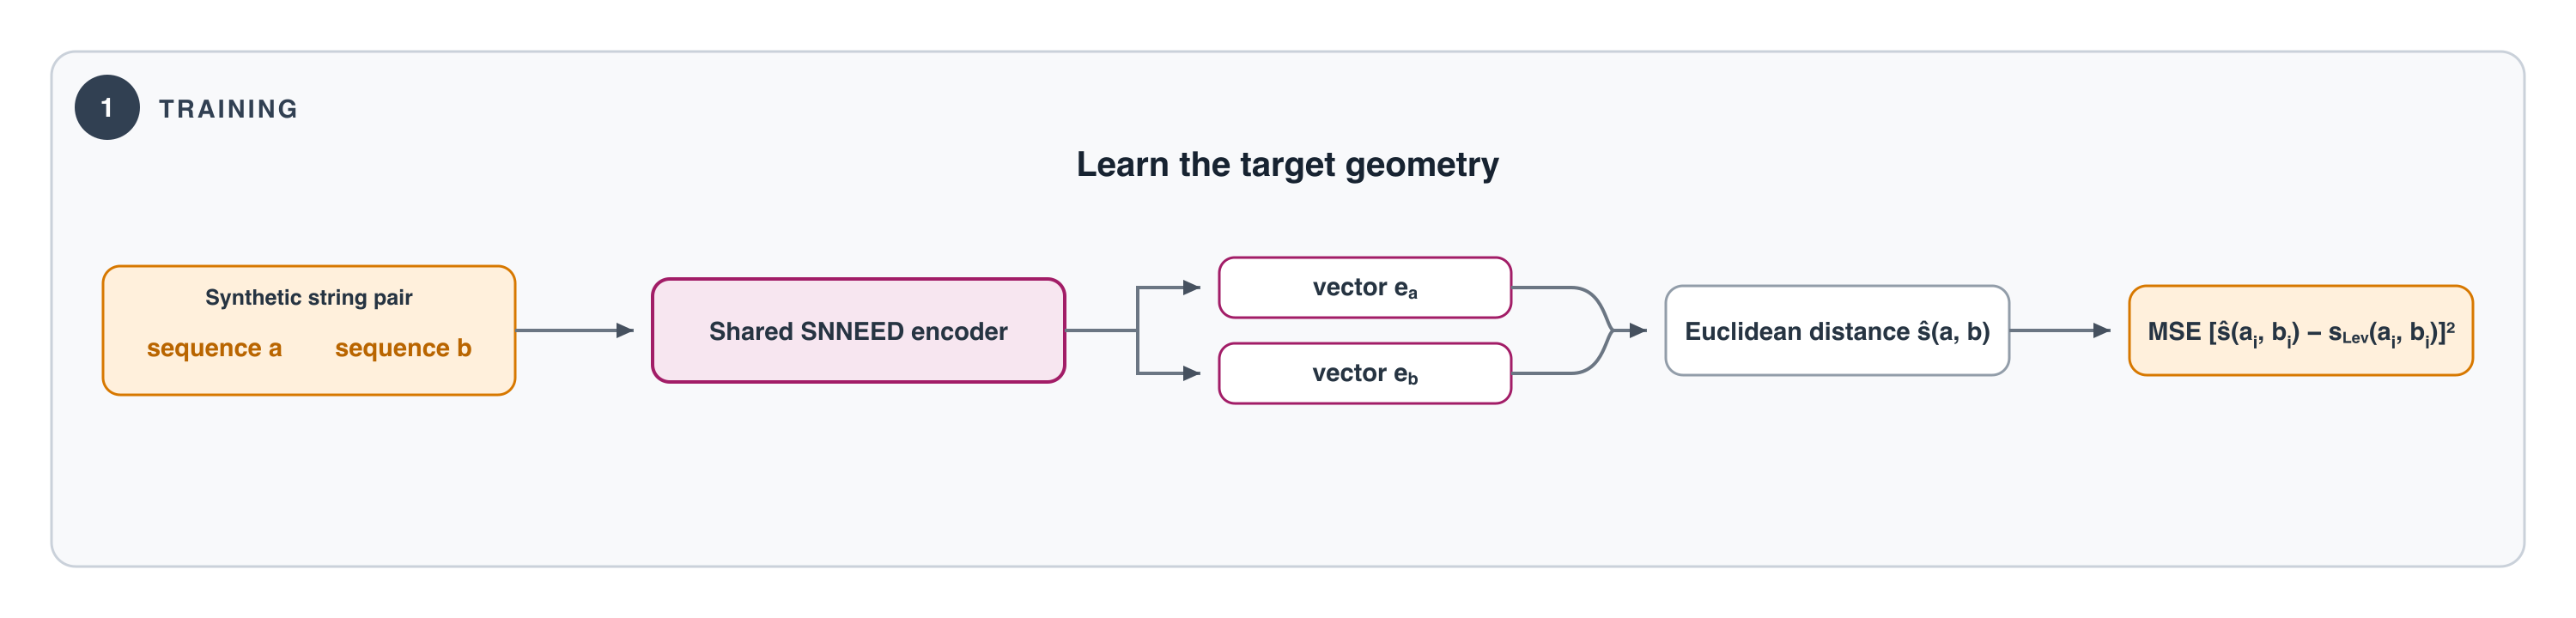

**Inside the Encoder 2.2.1**
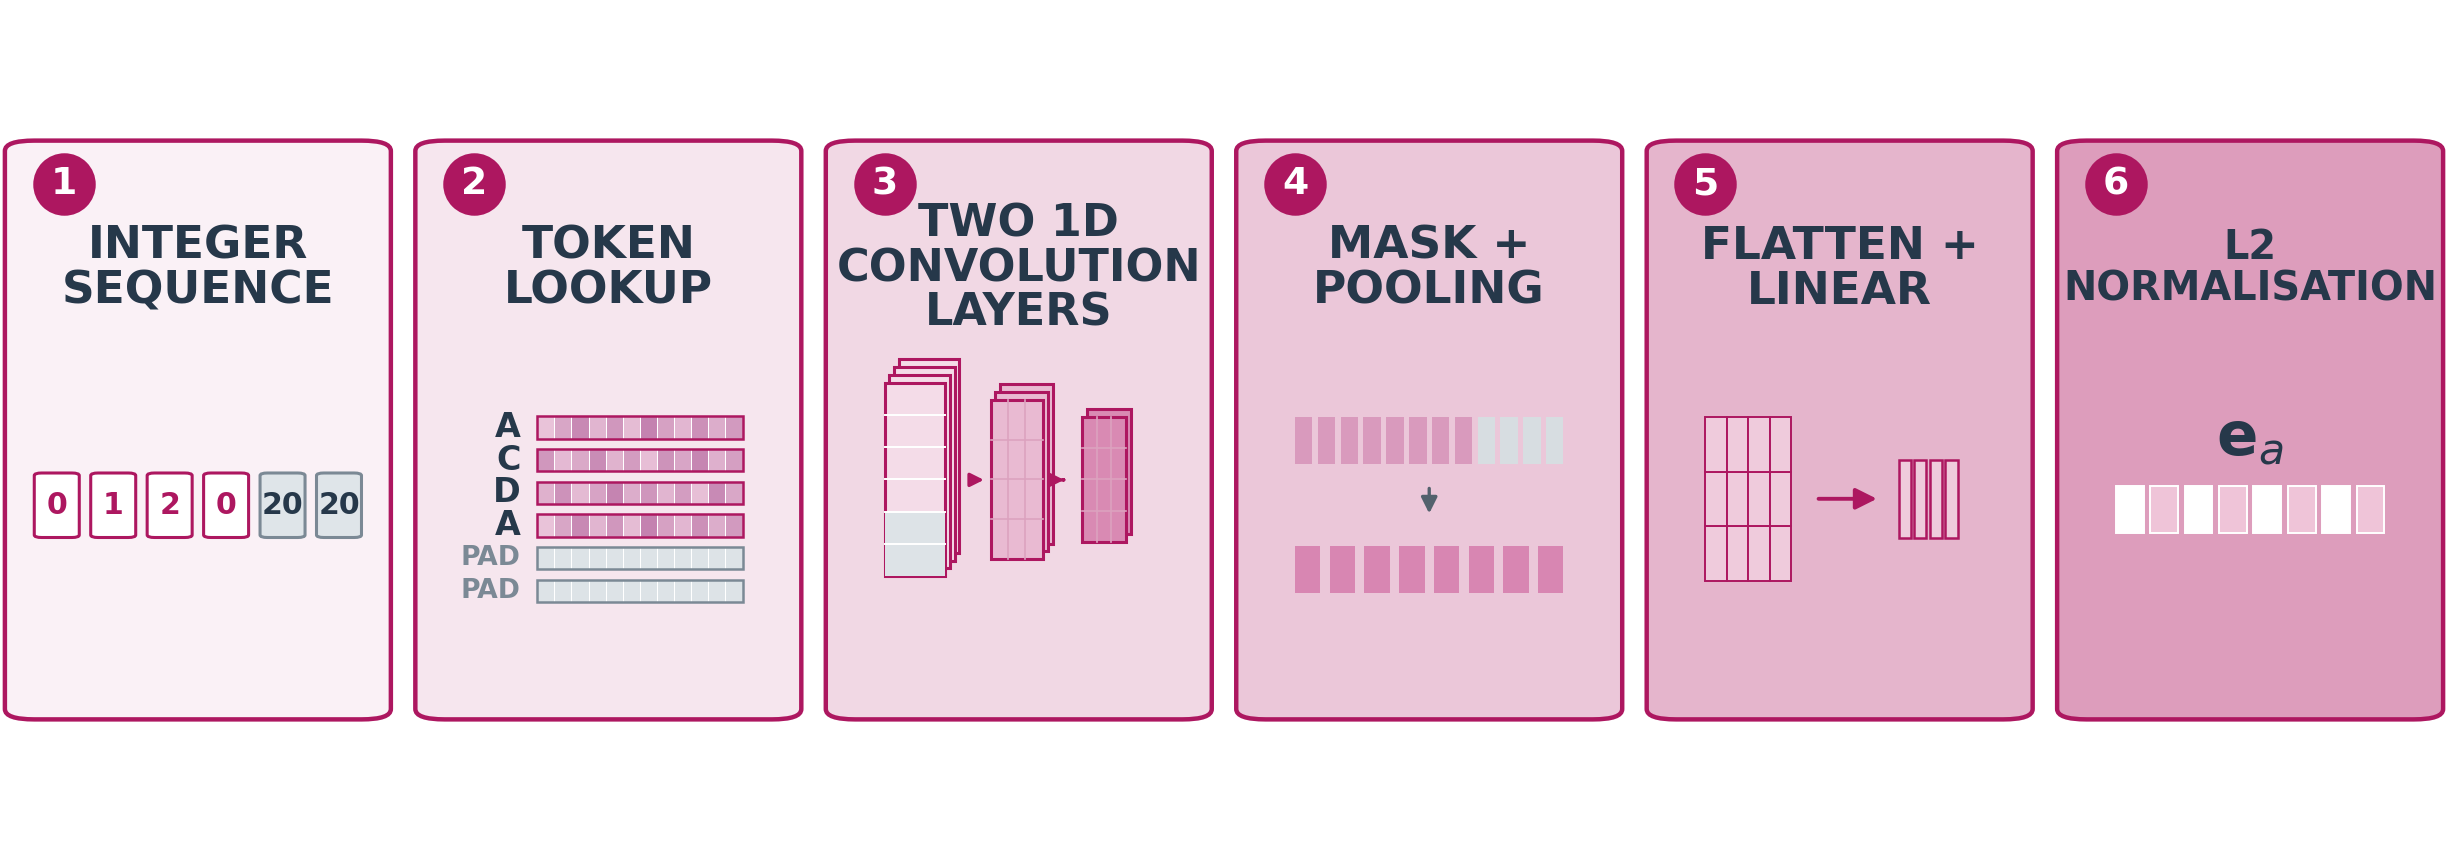

In [1]:
def encode_pad(seq):
    # turn each letter into its number
    numbers = []
    for letter in seq:
      number = CHAR_TO_IDX[letter]
      numbers.append(number)
    # if sequence is too long, cut it off at MAX_LEN, shouldn't happen because of pre-filter
    if len(numbers) > MAX_LEN:
      numbers = numbers[0:MAX_LEN]
    # if too short, fill remaining positions with padding number
    while len(numbers) < MAX_LEN:
      numbers.append(PAD_IDX)
    # turn list into a PyTorch tensor of whole numbers
    tensor = torch.tensor(numbers, dtype=torch.long)
    return tensor

'''
┌─────────────────────────────────────────┐
│                                         │
│   Siamese Neural Network Architecture   │
│                                         │
└─────────────────────────────────────────┘
'''

class EncPool(nn.Module): # 2.2.1
    def __init__(s):
        super().__init__()
        s.emb = nn.Embedding(VOCAB, 32, padding_idx=PAD_IDX)
        s.c1 = nn.Conv1d(32, 32, 3, padding=1)
        s.c2 = nn.Conv1d(32, 64, 3, padding=1)
        s.pool = nn.AdaptiveAvgPool1d(K)
        s.fc = nn.Linear(64 * K, 128)

    def forward(s, x):
        m = (x != PAD_IDX).float()
        e = s.emb(x).permute(0, 2, 1)
        h = F.relu(s.c1(e)) # relu activate convolutional layer
        h = F.relu(s.c2(h))
        h = h * m.unsqueeze(1)
        return F.normalize(s.fc(s.pool(h).flatten(1)), p=2, dim=1)

class RegModel(nn.Module):
    ''' Deployed SNNEED: chord readout, no head.
        The readout has no parameters.          '''
    def __init__(s, enc):
      super().__init__()
      s.encoder = enc

    def forward(s, a, b):
        ea, eb = s.encoder(a), s.encoder(b)
        return 1.0 - torch.linalg.vector_norm(ea - eb, ord=2, dim=1) / 2.0 # euclidean readout 2.2.2

class DS(Dataset):
    def __init__(s, pp): s.p = pp
    def __len__(s): return len(s.p)
    def __getitem__(s, i):
        a, b, l = s.p[i]
        return encode_pad(a), encode_pad(b), torch.tensor(l, dtype=torch.float32)


'''
┌─────────────────────────────────────────┐
│                                         │
│                Training                 │
│                                         │
└─────────────────────────────────────────┘
'''

def build_train_pairs(n, seed):

  '''
  For each random seed a new training dataset is generated and a new
  encoder is trained from random initialisation. A given seed reproduces
  the same training set.

  '''
  rng = np.random.default_rng(seed)
  pairs = []
  while len(pairs) < n:
    sd = rand_seq(AA_ALPHABET, rng)
    L = len(sd)
    t = float(rng.uniform(0, 1))
    k = max(0, int(round((1 - t) * L)))
    o = gen_seq(sd, k, AA_ALPHABET, rng)
    if 1 <= len(o) <= MAX_LEN:
      pairs.append((sd, o, norm_lev(sd, o)))
  return pairs

def train_snneed(seed):  # 2.3.3

    """
    The model is trained with the Adam optimiser using a fixed learning rate,
    with a batch size of 128, for 30 epochs over 30,000 training pairs. No
    separate validation split is held out for evaluation, and the parameters
    after the final epoch are used.

    Training is repeated for three seeds (0, 1, and 2), each controlling both
    the generation of the training pairs and the initialisation of the
    parameters. SNNEED results are reported as the arithmetic mean and standard
    deviation over these three independently trained encoders.
    """
    pairs = build_train_pairs(N_TRAIN, seed)

    torch.manual_seed(seed)

    model = RegModel(EncPool()).to(device)
    dl = DataLoader(
        DS(pairs),
        batch_size=BS,
        shuffle=True,
    )

    opt = torch.optim.Adam(
        model.parameters(),
        lr=LR,
    )

    model.train()
    t0 = time.time()

    for ep in range(EPOCHS):
        tot = 0.0

        for xa, xb, y in dl:
            xa = xa.to(device)
            xb = xb.to(device)
            y = y.to(device)

            # Unweighted loss — Section 2.3.2
            loss = F.mse_loss(model(xa, xb), y)

            opt.zero_grad()
            loss.backward()
            opt.step()

            tot += loss.item() * len(y)

        if (ep + 1) % 10 == 0:
            print(
                f"    seed {seed} "
                f"epoch {ep + 1:>2}/{EPOCHS} "
                f"loss {tot / len(pairs):.5f} "
                f"({time.time() - t0:.0f}s)"
            )

    return model.eval()


@torch.no_grad()
def embed(model, feed, bs=256):
  sequences = COLL[feed]
  all_embeddings = []
  with torch.no_grad():
    # no training here, so no gradients needed
    start = 0
    while start < len(sequences):
      end = start + bs
      batch_sequences = sequences[start:end] # the next 256 sequences (fewer at the end

      # turn each sequence into a padded tensor of numbers
      batch_tensors = []
      for s in batch_sequences:
        t = encode_pad(s)
        batch_tensors.append(t)

      # stack them into one matrix: (number_of_sequences, MAX_LEN)
      x = torch.stack(batch_tensors)
      x = x.to(device) # move to GPU if there is one
      # run the encoder -> one embedding vector per sequence
      embeddings = model.encoder(x)
      # move back to CPU and turn into numpy
      embeddings = embeddings.cpu().numpy()
      all_embeddings.append(embeddings)
      start = start + bs

    # glue all batches together into one big matrix: (number_of_sequences, embedding_size)
    result = np.concatenate(all_embeddings).astype(np.float32)
    return result

'''
┌─────────────────────────────────────────┐
│                                         │
│              SNNEED EVAL                │
│                                         │
└─────────────────────────────────────────┘
'''


ROWS = []
for seed in SEEDS:
    print(f'SNNEED seed {seed}')
    model = train_snneed(seed)
    for f in DATASETS:
        E = embed(model, f)
        P = STRAT[f]

        # pairwise euclidean distance readout a strictly decreasing fn of cosine similarity, ranking gives same order
        sim = np.sum(E[P['i']] * E[P['j']], axis=1)

        # As seen in 2.5, used in RMSE
        pred = 1.0 - np.linalg.norm(E[P['i']] - E[P['j']], axis=1) / 2.0

        # Function used to calculate retrieval scores for MAP@10
        # Et contains all N sequence embeddings, each with 128 dimensions
        Et = torch.as_tensor(E, device=device)

        def rows(qi):
          query_vector = Et[qi]                # the query's embedding, 128 numbers
          all_vectors = Et.t()                 # all embeddings, turned sideways: (128, N)
          scores = query_vector @ all_vectors  # dot product
          scores = scores.cpu().numpy().astype(np.float64)  # GPU -> CPU, tensor -> 64-bit numpy array
          return scores

        r = record('SNNEED', f, sim, P['nl'], map10_untied(rows, REL[f]['T_high']), pred=pred)
        r['seed'] = seed
        ROWS.append(r)
        print(f'    {f:<6} rho={r["spearman"]:+.3f} AUROC={r["auroc"]:.3f} '
              f'MAP@10={r["map10"]:.3f} RMSE_high={r["rmse_high"]:.3f}')

IndentationError: expected an indented block after function definition on line 76 (2169334994.py, line 78)

# ESM-2, Dice and Length for evaluation


1.   **The ESM-2** reference uses the pretrained 12-layer, 35-million-parameter model `esm2_t12_ 35M_UR50D`. Each sequence is processed using the model’s own tokeniser. The padding and the beginning- and end-of-sequence tokens are excluded. Its embedding is L2-normalised, using the same operation defined for SNNEED in Section 2.2.2. It therefore lies on the unit sphere, allowing that two sequences a and b are scored using their cosine similarity.
2.   **Dice** represents each sequence by its set of distinct, neighbouring 3-grams. The score lies in [0, 1]. A value of one indicates that both sequences contain the same set of distinct 3-grams, whereas a value of zero indicates that their sets do not overlap and the two sequences are therefore maximally dissimilar. The baseline therefore establishes how well sequence pairs can be ordered by similarity from the number of shared substrings of length three alone, without any learned representation.
3. **The length-ratio** baseline assigns similarity using only the lengths of the two sequences. This is the upper bound that Equation 2.2 already imposes on the target: two sequences of unequal length cannot exceed it whatever their contents. The baseline therefore measures how much of the internal embedding geometry mirroring sequence similarity can be explained by sequence length alone.



In [ ]:
'''
┌─────────────────────────────────────────┐
│                                         │
│                 ESM-2                   │
│                                         │
└─────────────────────────────────────────┘
'''
@torch.no_grad()
def esm_embed(feed, bs=32):
    from transformers import AutoModel, AutoTokenizer

    if "mdl" not in globals():
        globals()["tok"] = AutoTokenizer.from_pretrained(ESM2_MODEL)
        globals()["mdl"] = (
            AutoModel.from_pretrained(ESM2_MODEL)
            .to(device)
            .eval()
        )

    seqs = COLL[feed]

    # Sorting by length reduces the amount of padding within each batch.
    order = np.argsort([len(sequence) for sequence in seqs])

    # Embeddings will later be restored to their original sequence order.
    out = [None] * len(seqs)

    for i in range(0, len(order), bs):
        idx = order[i:i + bs]
        batch = [seqs[j] for j in idx]

        enc = tok(
            batch,
            return_tensors="pt",
            padding=True,
            add_special_tokens=True,
        ).to(device)

        h = mdl(**enc).last_hidden_state
        mask = enc["attention_mask"].clone()

        number_of_sequences = mask.shape[0]

        for row_index in range(number_of_sequences):
            # BOS is always the first token.
            mask[row_index, 0] = 0

            # Count the non-padding positions, including BOS and EOS.
            attention_row = enc["attention_mask"][row_index]
            sequence_length = int(attention_row.sum().item())

            # EOS is the final non-padding token.
            eos_position = sequence_length - 1
            mask[row_index, eos_position] = 0

        # Add a final dimension so the mask can be multiplied by h.
        m = mask.unsqueeze(-1).float()

        # Mean-pool the remaining sequence tokens and normalise the result.
        e = F.normalize(
            (h * m).sum(dim=1) / m.sum(dim=1).clamp(min=1),
            dim=1,
        ).cpu().numpy()

        # Restore each embedding to its position before length sorting.
        for batch_index, original_index in enumerate(idx):
            out[original_index] = e[batch_index]

    return np.stack(out).astype(np.float32)

for f in DATASETS:
    # Create one ESM-2 embedding for every sequence in dataset f.
    E = esm_embed(f)

    # Load the predefined pairs for pairwise evaluation.
    P = STRAT[f]

    # Calculate the cosine similarity for each pair.
    sim = np.sum(
        E[P["i"]] * E[P["j"]],
        axis=1,
    )

    # Convert the embeddings to a PyTorch tensor.
    Et = torch.as_tensor(
        E,
        device=device,
    )

    # Calculate the similarity between the selected queries
    # and every sequence in the dataset.
    def rows(qi):
        scores = Et[qi] @ Et.t()
        scores = scores.cpu().numpy()
        scores = scores.astype(np.float64)

        return scores

    # Calculate MAP@10.
    map10 = map10_untied(
        rows,
        REL[f]["T_high"],
    )

    # Calculate and store all evaluation metrics.
    r = record(
        "ESM-2",
        f,
        sim,
        P["nl"],
        map10,
    )

    ROWS.append(r)

    print(
        f'  ESM-2  {f:<6} '
        f'rho={r["spearman"]:+.3f} '
        f'AUROC={r["auroc"]:.3f} '
        f'MAP@10={r["map10"]:.3f}'
    )

In [ ]:
'''
┌─────────────────────────────────────────┐
│                                         │
│                 Dice                    │
│                                         │
└─────────────────────────────────────────┘
'''

def dice_matrix(sequences, k=3):
    # Give every distinct k-gram its own column number.
    vocabulary = {}

    # These lists record where the 1s will appear in the sparse matrix.
    row_indices = []
    column_indices = []

    for sequence_index, sequence in enumerate(sequences):
        grams_in_this_sequence = set()

        # Extract every substring of length k.
        number_of_grams = len(sequence) - k + 1

        for start_position in range(number_of_grams):
            gram = sequence[start_position:start_position + k]
            grams_in_this_sequence.add(gram)

        # Add each distinct gram only once for this sequence.
        for gram in grams_in_this_sequence:
            if gram not in vocabulary:
                new_column = len(vocabulary)
                vocabulary[gram] = new_column

            gram_column = vocabulary[gram]

            row_indices.append(sequence_index)
            column_indices.append(gram_column)

    # Every stored matrix entry has the value 1.
    values = np.ones(
        len(row_indices),
        dtype=np.float32,
    )

    number_of_rows = len(sequences)

    # Keep at least one column, even if no k-grams were found.
    number_of_columns = max(1, len(vocabulary))

    M = sparse.csr_matrix(
        (
            values,
            (row_indices, column_indices),
        ),
        shape=(
            number_of_rows,
            number_of_columns,
        ),
    )

    # Count the number of distinct k-grams in each sequence.
    gram_counts = np.asarray(
        M.sum(axis=1)
    ).ravel()

    return M, gram_counts


for f in DATASETS:

    '''
    Build the k-gram matrix for dataset.
    M: one row per sequence and one column per distinct k-gram.
    sz: number of distinct k-grams in each sequence.

    inter is the number of shared k-grams between A & B.
    sz[P["i"]] is |A|.
    sz[P["j"]] is |B|.
    np.maximum(..., 1e-9) prevents division by zero if both sequences contain no k-grams.
    rows(qi) applies the same Dice calculation between query qi and every sequence in the dataset.

    '''
    M, sz = dice_matrix(COLL[f])

    # Load the predefined pairs used for pairwise evaluation.
    P = STRAT[f]

    first_sequences = M[P["i"]]
    second_sequences = M[P["j"]]

    # Multiply corresponding rows element by element.
    # Because M contains only 0s and 1s, the sum is the number
    # of k-grams shared by the two sequences.
    shared_grams = first_sequences.multiply(second_sequences)
    inter = np.asarray(
        shared_grams.sum(axis=1)
    ).ravel().astype(float)

    # Calculate the Dice similarity for every predefined pair.
    pair_sizes = sz[P["i"]] + sz[P["j"]]

    sim = (
        2 * inter
        / np.maximum(pair_sizes, 1e-9)
    )

    # Calculate the Dice similarity between query qi
    # and every sequence in the dataset.
    def rows(qi):
        query_grams = M[qi]

        # The dot product counts the k-grams shared between
        # the query and every sequence.
        shared_with_query = M.dot(query_grams.T)

        it = (
            np.asarray(shared_with_query.todense())
            .ravel()
            .astype(np.float64)
        )

        query_and_sequence_sizes = sz + sz[qi]

        dice_scores = (
            2 * it
            / np.maximum(query_and_sequence_sizes, 1e-9)
        )

        return dice_scores

    # Calculate MAP@10 while accounting for tied Dice scores.
    m, sd = map10_tied(
        rows,
        REL[f]["T_high"],
    )

    # Calculate and store the remaining metrics.
    r = record(
        "Dice",
        f,
        sim,
        P["nl"],
        m,
        sd,
    )

    ROWS.append(r)

    print(
        f"  Dice   {f:<6} "
        f"MAP@10={m:.3f} "
        f"(tie sd {sd:.5f})"
    )

In [1]:
'''
┌─────────────────────────────────────────┐
│                                         │
│                 Length                  │
│                                         │
└─────────────────────────────────────────┘
'''

for f in DATASETS:
    # Get all sequences in the current dataset.
    sequences = COLL[f]

    # Record the length of every sequence.
    lens = np.array(
        [len(sequence) for sequence in sequences],
        dtype=np.float64,
    )

    # Load the predefined pairs used for pairwise evaluation.
    P = STRAT[f]

    first_lengths = lens[P["i"]]
    second_lengths = lens[P["j"]]

    # The similarity is the shorter length divided by the longer length.
    shorter_lengths = np.minimum(
        first_lengths,
        second_lengths,
    )

    longer_lengths = np.maximum(
        first_lengths,
        second_lengths,
    )

    sim = shorter_lengths / longer_lengths

    # Compare the length of query qi with the length of
    # every sequence in the dataset.
    def rows(qi):
        query_length = lens[qi]

        shorter_lengths = np.minimum(
            lens,
            query_length,
        )

        longer_lengths = np.maximum(
            lens,
            query_length,
        )

        length_scores = shorter_lengths / longer_lengths

        return length_scores

    # Calculate MAP@10 while accounting for tied length scores.
    m, sd = map10_tied(
        rows,
        REL[f]["T_high"],
    )

    # Calculate and store the remaining metrics.
    r = record(
        "Length",
        f,
        sim,
        P["nl"],
        m,
        sd,
    )

    ROWS.append(r)

    print(
        f"  Length {f:<6} "
        f"MAP@10={m:.3f} "
        f"(tie sd {sd:.5f})"
    )

'''
┌─────────────────────────────────────────┐
│                                         │
│ Create a table for all recorded results │
│                                         │
└─────────────────────────────────────────┘
'''

RES = pd.DataFrame(ROWS)


# Find the columns containing floating-point measurements.
float_columns = []

for column_name in RES.columns:
    if RES[column_name].dtype.kind == "f":
        float_columns.append(column_name)


# Specify that the mean should be calculated for each measurement.
mean_rules = {}

for column_name in float_columns:
    mean_rules[column_name] = "mean"


# Calculate the mean result for each method and dataset.
AGG = (
    RES
    .groupby(
        ["method", "dataset"],
        as_index=False,
    )
    .agg(mean_rules)
)


# Select only the results from the independently trained SNNEED models.
snneed_results = RES[
    RES["method"] == "SNNEED"
]


# Calculate the standard deviation across the SNNEED seeds.
SD = (
    snneed_results
    .groupby(
        "dataset",
        as_index=False,
    )
    .agg(
        spearman_sd=("spearman", "std"),
        auroc_sd=("auroc", "std"),
        map10_sd=("map10", "std"),
        rmse_sd=("rmse_high", "std"),
    )
)


# Save both the individual and averaged results.
RES.to_csv(
    "colab40_results_raw.csv",
    index=False,
)

AGG.to_csv(
    "colab40_results_mean.csv",
    index=False,
)


# Display the SNNEED standard deviations.
print(SD)

# Display the table containing the mean results.
AGG


NameError: name 'DATASETS' is not defined

# Figures

| Metric | Scale |
|---|---|
| Spearman | blue $-1$ → white $0$ → red $+1$ |
| MAP@10, AUROC | white $0$ → red $1$ |
| RMSE | **reversed** — low is red, so red always means good |

In [ ]:
'''
┌─────────────────────────────────────────┐
│                                         │
│ Chapter 4 - Figures 4.1, 4.2, 4.5, 4.6  │
│                                         │
└─────────────────────────────────────────┘
'''

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize

SRC = 'colab40_results_mean.csv'   # <- adjust, e.g. '/content/drive/MyDrive/.../colab40_results_mean.csv'
OUT = '.'                          # <- folder the PNGs are written to

METHODS  = ['SNNEED', 'ESM-2', 'Dice', 'Length']
DATASETS = ['Synth', '3Di', 'SS', 'AA']

# Chapter 4 palette - colours the dataset tick labels
DATASET_COLOR = {'Synth': '#FF7F0E', '3Di': '#0072B2', 'SS': '#D62728', 'AA': '#4D4D4D'}

SEQ = plt.get_cmap('Reds')         # AUROC and MAP@10, 0..1

def diverging():
    '''Blues-reversed | white | Reds, so the positive half matches SEQ exactly.'''
    neg = plt.get_cmap('Blues')(np.linspace(1.0, 0.0, 256))
    pos = SEQ(np.linspace(0.0, 1.0, 256))
    return LinearSegmentedColormap.from_list('BuWtRd', np.vstack([neg, pos]))

DIV = diverging()                  # Spearman, -1..1

df = pd.read_csv(SRC)
df = df.set_index(['method', 'dataset'])

def matrix(column):
    m = np.full((len(METHODS), len(DATASETS)), np.nan)
    for r, meth in enumerate(METHODS):
        for c, ds in enumerate(DATASETS):
            m[r, c] = df.loc[(meth, ds), column]
    return m

def heat(ax, mx, title, kind, ylabels=True, cbar=True, cbar_label=None):
    if kind == 'spearman':
        im = ax.imshow(mx, cmap=DIV, norm=Normalize(vmin=-1, vmax=1))
    else:
        im = ax.imshow(mx, cmap=SEQ, norm=Normalize(vmin=0, vmax=1))

    ax.set_xticks(range(len(DATASETS)), DATASETS)
    for tick, ds in zip(ax.get_xticklabels(), DATASETS):
        tick.set_color(DATASET_COLOR[ds])
    if ylabels:
        ax.set_yticks(range(len(METHODS)), METHODS)
    else:
        ax.set_yticks([])
    ax.set_title(title, fontsize=10)

    for r in range(len(METHODS)):
        for c in range(len(DATASETS)):
            v = mx[r, c]
            if not np.isfinite(v):                      # empty / suppressed cell
                ax.text(c, r, '--', ha='center', va='center', fontsize=8, color='0.55')
                continue
            shade = im.cmap(im.norm(v))[:3]             # white text on dark cells
            lum = 0.299 * shade[0] + 0.587 * shade[1] + 0.114 * shade[2]
            ax.text(c, r, f'{v:.2f}', ha='center', va='center',
                    fontsize=9, color='white' if lum < 0.55 else 'black')

    if cbar:
        cb = ax.figure.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cb.ax.tick_params(labelsize=8)
        if cbar_label:
            cb.set_label(cbar_label, fontsize=8)

# ---- Figure 4.1 - overall Spearman ----
fig, ax = plt.subplots(figsize=(5.8, 4.2))
heat(ax, matrix('spearman'), 'Spearman correlation', 'spearman', cbar_label=r'$\rho$')
fig.tight_layout()
fig.savefig(f'{OUT}/colab40_spearman.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- Figure 4.2 - Spearman by similarity range ----
# AA is blanked in the mid and high panels on purpose: only 11 / 5 AA pairs fall
# there, too few to report a coefficient (see section 5.2.1). The far panel keeps AA.
fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.4))
aa = DATASETS.index('AA')
for ax, rng in zip(axes, ['far', 'mid', 'high']):
    mx = matrix(f'spearman_{rng}')
    if rng in ('mid', 'high'):
        mx[:, aa] = np.nan
    heat(ax, mx, f'{rng} range', 'spearman', ylabels=(rng == 'far'))
fig.suptitle('Spearman correlation by similarity range', fontsize=11)
fig.tight_layout()
fig.savefig(f'{OUT}/colab40_spearman_by_range.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- Figure 4.5 - MAP@10 ----
fig, ax = plt.subplots(figsize=(5.8, 4.2))
heat(ax, matrix('map10'), 'MAP@10', 'unit', cbar_label='MAP@10')
fig.tight_layout()
fig.savefig(f'{OUT}/map10-results.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- Figure 4.6 - AUROC ----
fig, ax = plt.subplots(figsize=(5.8, 4.2))
heat(ax, matrix('auroc'), 'AUROC', 'unit', cbar_label='AUROC')
fig.tight_layout()
fig.savefig(f'{OUT}/auroc_results.png', dpi=200, bbox_inches='tight')
plt.show()